# SEM Wafer Defect Segmentation — U-Net++ with SSIM-Gated ±30° Rotation Augmentation, Weighted Loss & Threshold Tuning (Kaggle Notebook)

This notebook trains a **U-Net++** segmentation model on your SEM/wafer dataset (COCO-format, exported from Roboflow) and reports:

- **Training vs Validation loss curve**
- **Pixel-wise confusion matrix** on the test set
- **Comparison table**: Precision, Recall, Accuracy, F1-score for Train / Validation / Test

**What's in this version, aimed at raising F1:**
- **SSIM-gated ±30° rotation augmentation** (Step 8) — every training image gets a left (+30°) and a right (−30°) rotated copy; each copy is kept only if it passes a structural-similarity (SSIM) check against the original, so up to 3× the original images (original + 2 rotations, per image) are used, without training on degenerate/corrupted rotations
- **Class-weighted loss** (Step 10) — penalizes missed defect pixels proportionally to how rare they are in your data
- **F1-optimized checkpointing** (Step 12) — keeps the epoch with the best validation F1, not just the lowest loss
- **Validation-tuned decision threshold** (Step 13) — picks whichever threshold maximizes F1 instead of assuming 0.5

> **On your 85% F1 target:** I still can't guarantee that number — it depends on how visually separable the defect regions actually are in your images. What this version adds, on top of the previous round, is a more targeted augmentation aimed at the same recall problem your confusion matrix showed (precision ~97%, recall ~15% — the model was barely finding defect pixels at all):
> 1. **SSIM-gated ±30° rotation augmentation** (Step 8) — every training image gets a left (+30°) and right (−30°) rotated copy, each kept only if it passes a structural-similarity (SSIM) quality check against the original, so the model sees genuine new viewing angles without training on corrupted/degenerate rotations.
> 2. **Class-weighted loss** (Step 10) — computes the actual background:defect pixel ratio in your training set and weights the loss accordingly, so missed defect pixels are penalized more than false alarms.
> 3. **F1-optimized checkpointing** (Step 12) — saves whichever epoch has the best *validation F1*, not just the lowest validation loss.
> 4. **Tuned decision threshold** (Step 13) — sweeps thresholds on the validation set and uses whichever one maximizes F1, instead of assuming the default 0.5.
>
> Run the notebook and read the actual Test F1 in Step 15 / Step 17 — that's the real number, not something I can promise in advance.

**Your dataset structure (as provided):**
```
0.coco/
├── train/
│   ├── _annotations.coco.json
│   └── *.jpg   (67 images)
├── test/
│   ├── _annotations.coco.json
│   └── *.jpg   (9 images)
└── valid/
    ├── _annotations.coco.json
    └── *.jpg   (19 images)
```

> **Dataset size:** 67 train / 19 valid / 9 test images — the largest of your four splits, and a reasonably workable size for fine-tuning a pretrained encoder. Expect this to give the most stable, trustworthy metrics of the four notebooks.

### Before you start on Kaggle
1. Zip your dataset folder (keep the `train/valid/test` structure inside) and go to **Kaggle → Datasets → New Dataset**, upload it. Give it any name, e.g. `sem-wafer-dataset`.
2. Open a new Notebook, click **Add Input → Datasets**, and attach the dataset you just created.
3. Go to **Settings (right panel) → Accelerator → GPU T4 x2 (or P100)**. Segmentation training needs a GPU.
4. Run the cells top to bottom. The dataset path is auto-detected in Step 3, but double check the printed path is correct.


## Step 1 — Install Dependencies

`segmentation-models-pytorch` gives us a ready-made U-Net++ implementation with pretrained encoders. `pycocotools` lets us turn your COCO polygon annotations into pixel masks. `albumentations` handles image+mask augmentation together. `scikit-image` provides the SSIM metric used to quality-gate the rotation augmentation in Step 8.

In [81]:
!pip install -q segmentation-models-pytorch pycocotools albumentations opencv-python-headless seaborn scikit-image

## Step 2 — Imports

In [82]:
import os
import glob
import random
import json

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp
from pycocotools.coco import COCO
from skimage.metrics import structural_similarity as ssim_metric

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Torch: 2.10.0+cu128 | CUDA available: True


## Step 3 — Locate the Dataset

Kaggle mounts attached datasets under `/kaggle/input/<dataset-name>/...`. This cell searches for your `train/_annotations.coco.json` automatically so you don't have to hardcode the dataset name. If auto-detection fails (prints `None`), edit `DATA_DIR` manually to match the path shown in the notebook's **Input** panel on the right.

In [83]:
def find_dataset_root():
    candidates = glob.glob('/kaggle/input/**/train/_annotations.coco.json', recursive=True)
    if candidates:
        # .../0.coco/train/_annotations.coco.json -> return .../0.coco
        return os.path.dirname(os.path.dirname(candidates[0]))
    return None

DATA_DIR = find_dataset_root()
if DATA_DIR is None:
    # Fallback — set this manually to match your uploaded Kaggle dataset folder name
    DATA_DIR = '/kaggle/input/sem-wafer-dataset/0.coco'
print("Detected dataset root:", DATA_DIR)

TRAIN_DIR = os.path.join(DATA_DIR, 'train')
VALID_DIR = os.path.join(DATA_DIR, 'valid')
TEST_DIR  = os.path.join(DATA_DIR, 'test')

TRAIN_ANN = os.path.join(TRAIN_DIR, '_annotations.coco.json')
VALID_ANN = os.path.join(VALID_DIR, '_annotations.coco.json')
TEST_ANN  = os.path.join(TEST_DIR, '_annotations.coco.json')

for p in [TRAIN_ANN, VALID_ANN, TEST_ANN]:
    print(p, "->", "FOUND" if os.path.exists(p) else "MISSING")

Detected dataset root: /kaggle/input/datasets/sarthakjadhav07/new-sem-dataset/SEM wafer dataset-Folder- 0.coco
/kaggle/input/datasets/sarthakjadhav07/new-sem-dataset/SEM wafer dataset-Folder- 0.coco/train/_annotations.coco.json -> FOUND
/kaggle/input/datasets/sarthakjadhav07/new-sem-dataset/SEM wafer dataset-Folder- 0.coco/valid/_annotations.coco.json -> FOUND
/kaggle/input/datasets/sarthakjadhav07/new-sem-dataset/SEM wafer dataset-Folder- 0.coco/test/_annotations.coco.json -> FOUND


## Step 4 — Explore the COCO Annotations

Quick sanity check: how many images/annotations per split, and what classes exist. Your file names (`0class_sorted_*`) suggest a single defect class — this notebook is built for **binary segmentation** (defect vs. background). If your `_annotations.coco.json` actually has more than one category, see the note at the end of Step 6 for how to extend it to multi-class.

In [84]:
coco_train = COCO(TRAIN_ANN)
coco_valid = COCO(VALID_ANN)
coco_test  = COCO(TEST_ANN)

print(f"Train images: {len(coco_train.imgs):3d} | annotations: {len(coco_train.anns)}")
print(f"Valid images: {len(coco_valid.imgs):3d} | annotations: {len(coco_valid.anns)}")
print(f"Test  images: {len(coco_test.imgs):3d} | annotations: {len(coco_test.anns)}")

cats = coco_train.loadCats(coco_train.getCatIds())
print("\nCategories found in train set:")
for c in cats:
    print(f"  id={c['id']}  name={c['name']}  supercategory={c.get('supercategory', '')}")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Train images:  67 | annotations: 75
Valid images:  19 | annotations: 18
Test  images:   9 | annotations: 10

Categories found in train set:
  id=0  name=SEM-wafer-dataset  supercategory=none
  id=1  name=SEM-wafer-dataset  supercategory=SEM-wafer-dataset


## Step 5 — Check for Malformed Annotations, then Visualize Samples

Roboflow COCO exports occasionally contain a stray annotation with an empty or degenerate polygon (fewer than 3 points) — `pycocotools` throws an `IndexError` on these instead of skipping them. This cell scans every split up front and reports how many annotations are invalid, so training won't crash on one later. `is_valid_segmentation()` is reused everywhere a mask gets built.

In [85]:
def is_valid_segmentation(seg):
    """A segmentation is either an RLE dict (crowd annotations) or a list of
    polygons, where every polygon needs at least 3 points (6 coordinates,
    x1,y1,x2,y2,...) and an even number of coordinates."""
    if not seg:
        return False
    if isinstance(seg, dict):  # RLE
        return True
    if not isinstance(seg, list):
        return False
    for poly in seg:
        if not isinstance(poly, list) or len(poly) < 6 or len(poly) % 2 != 0:
            return False
    return True

def audit_annotations(coco, split_name):
    bad = 0
    for ann in coco.anns.values():
        if not is_valid_segmentation(ann.get('segmentation')):
            bad += 1
    print(f"{split_name}: {len(coco.anns)} annotations, {bad} invalid (will be skipped)")

audit_annotations(coco_train, 'Train')
audit_annotations(coco_valid, 'Valid')
audit_annotations(coco_test, 'Test')

Train: 75 annotations, 2 invalid (will be skipped)
Valid: 18 annotations, 0 invalid (will be skipped)
Test: 10 annotations, 0 invalid (will be skipped)


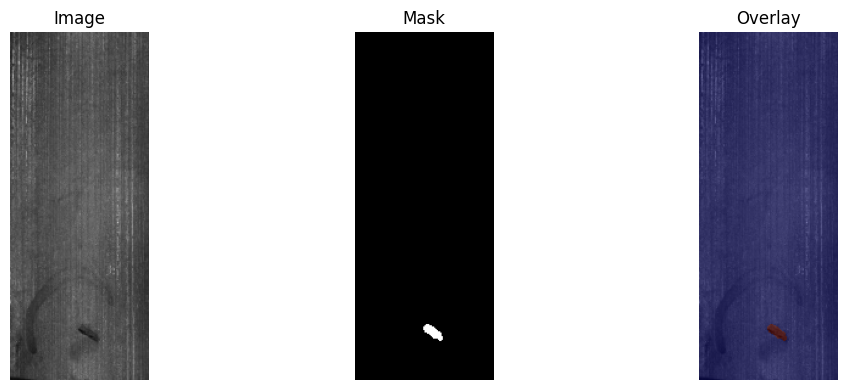

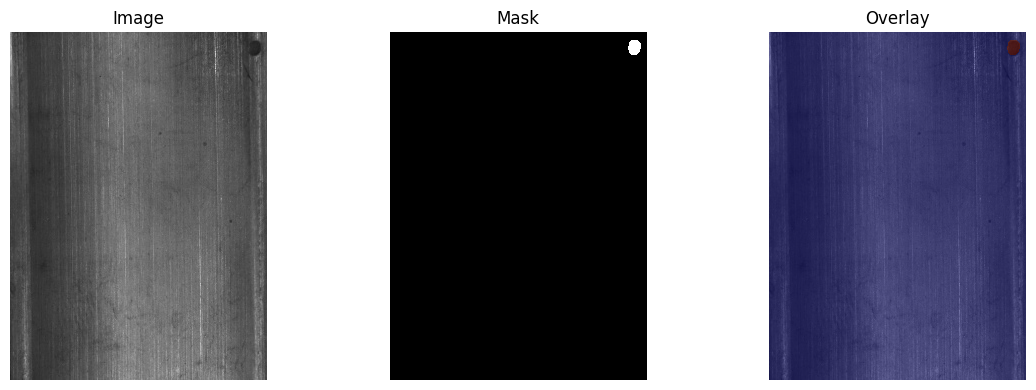

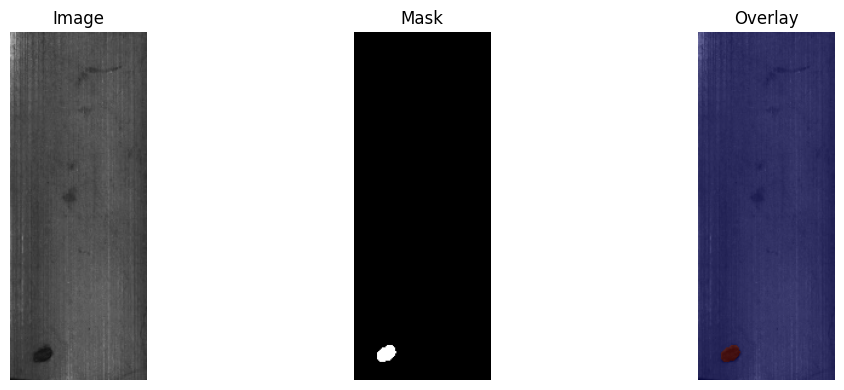

In [86]:
def build_mask(coco, img_id):
    img_info = coco.imgs[img_id]
    ann_ids = coco.getAnnIds(imgIds=img_id)
    anns = coco.loadAnns(ann_ids)
    mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
    for ann in anns:
        if not is_valid_segmentation(ann.get('segmentation')):
            continue
        try:
            mask[coco.annToMask(ann) > 0] = 1
        except Exception as e:
            print(f"  Skipping bad annotation {ann.get('id')} in image {img_id}: {e}")
    return mask

def show_sample(coco, images_dir, img_id):
    img_info = coco.imgs[img_id]
    image = cv2.imread(os.path.join(images_dir, img_info['file_name']))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    mask = build_mask(coco, img_id)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(image); axes[0].set_title('Image'); axes[0].axis('off')
    axes[1].imshow(mask, cmap='gray'); axes[1].set_title('Mask'); axes[1].axis('off')
    axes[2].imshow(image); axes[2].imshow(mask, cmap='jet', alpha=0.4)
    axes[2].set_title('Overlay'); axes[2].axis('off')
    plt.tight_layout(); plt.show()

sample_ids = list(coco_train.imgs.keys())[:3]
for sid in sample_ids:
    show_sample(coco_train, TRAIN_DIR, sid)

## Step 6 — PyTorch Dataset (COCO polygons → binary mask)

Each `__getitem__` reads the image, rasterizes all annotations for that image into a single binary mask (1 = defect, 0 = background), then applies the same augmentation to both image and mask together (so a flip on the image flips the mask too).

> **Multi-class note:** if your export actually has more than one defect category, replace `mask[m > 0] = 1` with `mask[m > 0] = ann['category_id']`, set `classes=len(cats)` in the model (Step 9), and swap the loss/metrics to their multi-class versions (`nn.CrossEntropyLoss`, `sklearn`'s multi-class confusion matrix).

In [87]:
class COCOSegDataset(Dataset):
    def __init__(self, images_dir, ann_file, transform=None):
        self.images_dir = images_dir
        self.coco = COCO(ann_file)
        self.image_ids = list(sorted(self.coco.imgs.keys()))
        self.transform = transform

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_info = self.coco.imgs[img_id]
        img_path = os.path.join(self.images_dir, img_info['file_name'])

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)

        mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
        for ann in anns:
            if not is_valid_segmentation(ann.get('segmentation')):
                continue  # skip malformed/degenerate polygons instead of crashing
            try:
                m = self.coco.annToMask(ann)
                mask[m > 0] = 1  # binary: defect vs background
            except Exception:
                continue

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        mask = mask.long()
        return image, mask

## Step 7 — Augmentations

Only 67 training images, so augmentation matters. Rotation is handled separately and deterministically in Step 8 (exactly ±30°, quality-gated by SSIM), so it's deliberately left out here to avoid compounding two different rotation schemes on the same image. `train_transform` covers everything else: flips (no canonical "up" direction on a wafer surface) plus mild brightness/contrast and noise jitter to mimic SEM imaging variation. Validation/test only get resize + normalize — no randomness, so metrics stay reproducible.

In [88]:
IMG_SIZE = 256

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.GaussNoise(p=0.2),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

eval_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

## Step 8 — Datasets & DataLoaders (SSIM-Gated ±30° Rotation Augmentation)

For every training image this builds a **left rotation (+30°)** and a **right rotation (−30°)**, alongside the original — up to 3× the training images. Rotation uses `cv2.warpAffine` with reflect-padding (`BORDER_REFLECT_101`) so corners don't turn into flat black regions that would introduce fake "background" — the mask is rotated with the same matrix using nearest-neighbor interpolation so it stays binary.

**Where SSIM comes in:** rotating an image by 30° inevitably shifts its structure somewhat — that's expected and fine. What SSIM (Structural Similarity Index) catches is the degenerate case: a rotation that came out mostly blank, corrupted, or otherwise nothing like the original. Each rotated copy is compared to its source image with `skimage`'s `structural_similarity`, and only kept if the score clears `min_ssim = 0.15` — a lenient bar that's a safety net, not a strict quality filter, since 30° rotation naturally drops SSIM well below 1.0 even for a perfectly good augmentation. The kept/rejected counts print below so you can see how many of each dataset's rotations passed.

This replaces the earlier "duplicate-draw" augmentation from the previous version of this notebook with something more literal and controllable, per your request. Rotations are computed **once** at dataset construction (they're deterministic, unlike the random flips/brightness jitter in `train_transform`, which still apply on top of each rotated copy at load time).

`train_loader_eval` (built on the plain, un-rotated dataset with `eval_transform`) is only used to score the model on **clean, original** training images for the comparison table in Step 17 — so that "Train" row isn't inflated by the rotated copies.

In [89]:
set_seed_value = 42
random.seed(set_seed_value)
np.random.seed(set_seed_value)
torch.manual_seed(set_seed_value)
torch.cuda.manual_seed_all(set_seed_value)

def rotate_image_and_mask(image, mask, angle):
    """Rotate an image and its mask by `angle` degrees about the image
    center. Positive angle = counter-clockwise ('left'), negative = clockwise
    ('right') in OpenCV's convention. Reflect-padding avoids introducing
    black corners; the mask uses nearest-neighbor interpolation to stay binary."""
    h, w = image.shape[:2]
    center = (w / 2.0, h / 2.0)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated_image = cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR,
                                    borderMode=cv2.BORDER_REFLECT_101)
    rotated_mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST,
                                   borderMode=cv2.BORDER_REFLECT_101)
    return rotated_image, rotated_mask

def compute_ssim(img1, img2):
    """Grayscale SSIM between two same-size uint8 images."""
    gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)
    score = ssim_metric(gray1, gray2, data_range=255)
    return score

class SSIMRotationAugmentedDataset(Dataset):
    """For every base training image, adds a +30 deg (left) and a -30 deg
    (right) rotated copy, each kept only if its SSIM against the original
    clears `min_ssim`. Rotations are precomputed once in __init__ since
    they're deterministic; `transform` (flips/brightness/noise) is still
    applied fresh on every __getitem__ call, including to the rotated copies."""
    def __init__(self, images_dir, ann_file, transform, angles=(30, -30), min_ssim=0.15):
        self.images_dir = images_dir
        self.coco = COCO(ann_file)
        self.transform = transform
        self.samples = []

        image_ids = list(sorted(self.coco.imgs.keys()))
        kept, rejected = 0, 0

        for img_id in image_ids:
            img_info = self.coco.imgs[img_id]
            img_path = os.path.join(images_dir, img_info['file_name'])
            image = cv2.imread(img_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            ann_ids = self.coco.getAnnIds(imgIds=img_id)
            anns = self.coco.loadAnns(ann_ids)
            mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
            for ann in anns:
                if not is_valid_segmentation(ann.get('segmentation')):
                    continue
                try:
                    mask[self.coco.annToMask(ann) > 0] = 1
                except Exception:
                    continue

            self.samples.append((image, mask))  # original, unrotated

            for angle in angles:
                rot_image, rot_mask = rotate_image_and_mask(image, mask, angle)
                score = compute_ssim(image, rot_image)
                if score >= min_ssim:
                    self.samples.append((rot_image, rot_mask))
                    kept += 1
                else:
                    rejected += 1

        print(f"SSIM-gated rotation augmentation: {len(image_ids)} original images -> "
              f"{kept} rotated copies kept, {rejected} rejected (SSIM < {min_ssim}) "
              f"-> {len(self.samples)} total training samples/epoch")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image, mask = self.samples[idx]
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']
        mask = mask.long()
        return image, mask

BATCH_SIZE = 4
NUM_WORKERS = 2

train_dataset      = SSIMRotationAugmentedDataset(TRAIN_DIR, TRAIN_ANN, transform=train_transform,
                                                   angles=(30, -30), min_ssim=0.15)
train_dataset_eval = COCOSegDataset(TRAIN_DIR, TRAIN_ANN, transform=eval_transform)
valid_dataset       = COCOSegDataset(VALID_DIR, VALID_ANN, transform=eval_transform)
test_dataset        = COCOSegDataset(TEST_DIR, TEST_ANN, transform=eval_transform)

train_loader      = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
train_loader_eval = DataLoader(train_dataset_eval, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
valid_loader      = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader       = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"Valid: {len(valid_dataset)} | Test: {len(test_dataset)}")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
SSIM-gated rotation augmentation: 67 original images -> 133 rotated copies kept, 1 rejected (SSIM < 0.15) -> 200 total training samples/epoch
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Valid: 19 | Test: 9


## Step 9 — Build U-Net++

`segmentation_models_pytorch.UnetPlusPlus` with a ResNet-34 encoder pretrained on ImageNet — a good default for small datasets since the encoder doesn't need to be learned from scratch. `classes=1` + no activation because we'll apply `sigmoid` inside the loss/metric functions (numerically more stable than baking it into the model).

In [90]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

model = smp.UnetPlusPlus(
    encoder_name='resnet34',
    encoder_weights='imagenet',
    in_channels=3,
    classes=1,
    activation=None,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"U-Net++ (resnet34 encoder) — trainable params: {n_params:,}")

Device: cuda
U-Net++ (resnet34 encoder) — trainable params: 26,078,609


## Step 10 — Class-Weighted Loss & Optimizer

**Dice + weighted BCE** combined loss. Your earlier confusion matrix showed the core problem clearly: precision was high (~97%) but recall was low (~15%) — the model was confidently right on the defect pixels it did predict, but missed most of the actual defect region. Plain BCE treats every pixel equally, which lets the model get away with predicting mostly background since background pixels dominate. This cell computes the actual background:defect pixel ratio in your training data and passes it to `BCEWithLogitsLoss` as `pos_weight`, so a missed defect pixel now costs proportionally more than a false alarm — directly pushing the model to raise recall (at some precision cost), which should raise F1 if that trade lands well.

**AdamW** is used instead of plain Adam — it decouples weight decay from the gradient update (rather than folding it into the gradient like Adam's L2 penalty does), which tends to regularize better and is the more common default for fine-tuning pretrained encoders like the ResNet-34 backbone here.

In [91]:
def compute_pos_weight(loader, max_weight=50.0):
    """Background:defect pixel ratio in a loader's masks, used to weight
    the loss toward the minority (defect) class. Capped at max_weight to
    avoid instability if a split is extremely imbalanced."""
    pos = 0
    neg = 0
    for _, masks in loader:
        pos += masks.sum().item()
        neg += (masks == 0).sum().item()
    ratio = neg / (pos + 1e-7)
    return min(ratio, max_weight)

pos_weight_value = compute_pos_weight(train_loader_eval)
print(f"Background:defect pixel ratio (pos_weight): {pos_weight_value:.2f}")

class DiceBCELoss(nn.Module):
    def __init__(self, pos_weight=None, smooth=1.0):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice_loss = 1 - (2. * intersection + self.smooth) / (
            probs_flat.sum() + targets_flat.sum() + self.smooth
        )
        return bce_loss + dice_loss

pos_weight_tensor = torch.tensor([pos_weight_value], device=device)
criterion = DiceBCELoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

Background:defect pixel ratio (pos_weight): 50.00


## Step 11 — Metrics: Precision / Recall / Accuracy / F1

All four metrics come from the same **pixel-wise confusion matrix** (TP, FP, FN, TN), accumulated over every pixel in every image of a split — this is why metrics stay computable even with a 9-image test set and 19-image validation set, since each image still contributes thousands of pixel-level samples. `evaluate()` returns both the loss (used for the loss curve) and this metrics dict (used for the confusion matrix and comparison table) in one pass.

In [92]:
@torch.no_grad()
def evaluate(model, loader, device, criterion, threshold=0.5):
    model.eval()
    running_loss = 0.0
    tp = fp = fn = tn = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device).unsqueeze(1).float()

        logits = model(images)
        loss = criterion(logits, masks)
        running_loss += loss.item() * images.size(0)

        preds = (torch.sigmoid(logits) > threshold).float()
        tp += ((preds == 1) & (masks == 1)).sum().item()
        fp += ((preds == 1) & (masks == 0)).sum().item()
        fn += ((preds == 0) & (masks == 1)).sum().item()
        tn += ((preds == 0) & (masks == 0)).sum().item()

    avg_loss = running_loss / len(loader.dataset)
    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-7)
    f1 = 2 * precision * recall / (precision + recall + 1e-7)

    return {
        'loss': avg_loss,
        'precision': precision,
        'recall': recall,
        'accuracy': accuracy,
        'f1': f1,
        'confusion_matrix': np.array([[tn, fp], [fn, tp]]),
    }

## Step 12 — Train

Trains for a fixed number of epochs, tracking train/validation loss each epoch. Checkpointing is now based on **best validation F1**, not lowest validation loss — since F1 is the actual metric you're optimizing for, the two don't always agree on which epoch is "best." `EPOCHS = 40`. Each epoch now runs over more than the original 67 training samples thanks to the SSIM-approved rotations from Step 8 (up to 201 if every rotation passes the SSIM check — see the exact count printed there).

In [93]:
EPOCHS = 40

history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
best_val_f1 = -1.0
best_val_loss_at_best_f1 = None
CKPT_PATH = 'best_unetpp_sem_wafer_ssimrot30_f1boost.pth'

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device).unsqueeze(1).float()

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)
    val_metrics = evaluate(model, valid_loader, device, criterion)
    val_loss = val_metrics['loss']

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_metrics['f1'])
    scheduler.step(val_metrics['f1'])

    if val_metrics['f1'] > best_val_f1:
        best_val_f1 = val_metrics['f1']
        best_val_loss_at_best_f1 = val_loss
        torch.save(model.state_dict(), CKPT_PATH)

    print(f"Epoch {epoch:2d}/{EPOCHS} | Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val F1: {val_metrics['f1']:.4f}")

print(f"\nBest validation F1: {best_val_f1:.4f} (val loss at that epoch: {best_val_loss_at_best_f1:.4f}) "
      f"— checkpoint saved to {CKPT_PATH}")

Epoch  1/40 | Train Loss: 1.4192 | Val Loss: 1.2992 | Val F1: 0.1813
Epoch  2/40 | Train Loss: 1.2704 | Val Loss: 1.2059 | Val F1: 0.2739
Epoch  3/40 | Train Loss: 1.1832 | Val Loss: 1.1503 | Val F1: 0.4293
Epoch  4/40 | Train Loss: 1.1267 | Val Loss: 1.0983 | Val F1: 0.3545
Epoch  5/40 | Train Loss: 1.0867 | Val Loss: 1.0615 | Val F1: 0.5079
Epoch  6/40 | Train Loss: 1.0646 | Val Loss: 1.0317 | Val F1: 0.4003
Epoch  7/40 | Train Loss: 1.0321 | Val Loss: 1.0011 | Val F1: 0.4334
Epoch  8/40 | Train Loss: 1.0041 | Val Loss: 1.0024 | Val F1: 0.2973
Epoch  9/40 | Train Loss: 0.9836 | Val Loss: 0.9486 | Val F1: 0.5636
Epoch 10/40 | Train Loss: 0.9705 | Val Loss: 0.9072 | Val F1: 0.4996
Epoch 11/40 | Train Loss: 0.9309 | Val Loss: 0.8682 | Val F1: 0.6092
Epoch 12/40 | Train Loss: 0.8916 | Val Loss: 0.8337 | Val F1: 0.6902
Epoch 13/40 | Train Loss: 0.8496 | Val Loss: 0.7782 | Val F1: 0.6730
Epoch 14/40 | Train Loss: 0.7667 | Val Loss: 0.6732 | Val F1: 0.7022
Epoch 15/40 | Train Loss: 0.7427 |

## Step 13 — Tune the Decision Threshold

The model outputs a probability per pixel; turning that into a binary mask requires a threshold, and 0.5 is just a default, not necessarily what maximizes F1. This sweeps thresholds from 0.05 to 0.95 on the **validation set only** (never the test set — that would leak test information into a choice that affects the reported test metrics) and keeps whichever threshold gives the best validation F1. That threshold is then reused for every test-set evaluation from here on.

Best threshold on validation set: 0.45 | Val F1: 0.8324 | Val Precision: 0.7791 | Val Recall: 0.8935


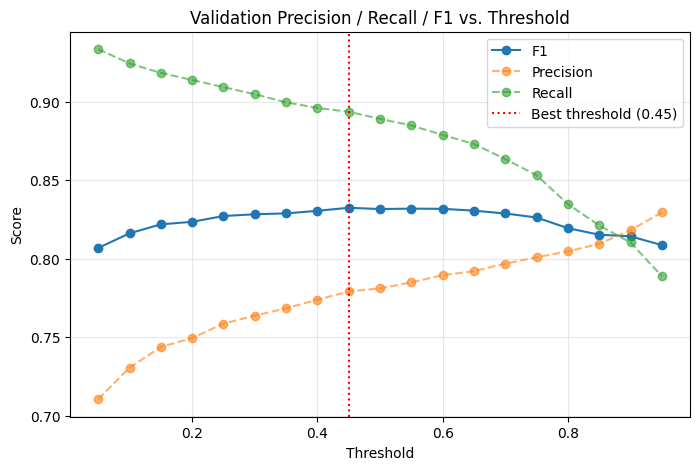

In [94]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))

def sweep_thresholds(model, loader, device, criterion, thresholds):
    rows = []
    for thr in thresholds:
        m = evaluate(model, loader, device, criterion, threshold=thr)
        rows.append({'threshold': thr, 'f1': m['f1'], 'precision': m['precision'], 'recall': m['recall']})
    return pd.DataFrame(rows)

thresholds = np.arange(0.05, 1.0, 0.05)
sweep_df = sweep_thresholds(model, valid_loader, device, criterion, thresholds)

best_row = sweep_df.loc[sweep_df['f1'].idxmax()]
BEST_THRESHOLD = float(best_row['threshold'])
print(f"Best threshold on validation set: {BEST_THRESHOLD:.2f} | "
      f"Val F1: {best_row['f1']:.4f} | Val Precision: {best_row['precision']:.4f} | Val Recall: {best_row['recall']:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(sweep_df['threshold'], sweep_df['f1'], marker='o', label='F1')
plt.plot(sweep_df['threshold'], sweep_df['precision'], marker='o', linestyle='--', alpha=0.6, label='Precision')
plt.plot(sweep_df['threshold'], sweep_df['recall'], marker='o', linestyle='--', alpha=0.6, label='Recall')
plt.axvline(BEST_THRESHOLD, color='red', linestyle=':', label=f'Best threshold ({BEST_THRESHOLD:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Validation Precision / Recall / F1 vs. Threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('threshold_sweep_ssimrot30_f1boost.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 14 — Loss Curve

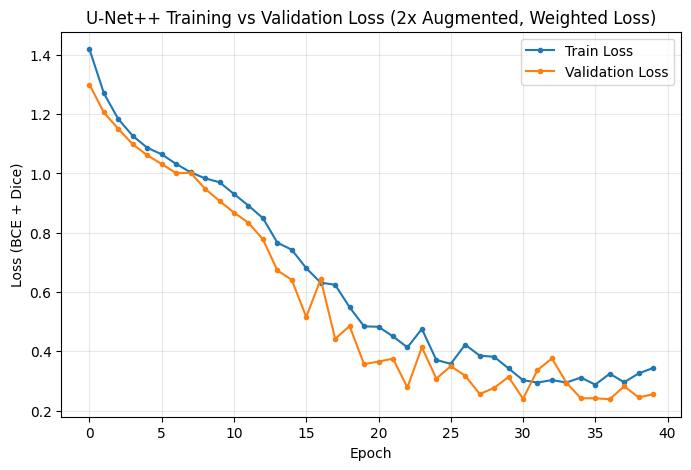

In [95]:
plt.figure(figsize=(8, 5))
plt.plot(history['train_loss'], label='Train Loss', marker='o', markersize=3)
plt.plot(history['val_loss'], label='Validation Loss', marker='o', markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Loss (BCE + Dice)')
plt.title('U-Net++ Training vs Validation Loss (2x Augmented, Weighted Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('loss_curve_ssimrot30_f1boost.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 15 — Evaluate on Test Set (Best Checkpoint, Tuned Threshold)

In [96]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))  # defensive reload
test_metrics = evaluate(model, test_loader, device, criterion, threshold=BEST_THRESHOLD)

print(f"Threshold used:  {BEST_THRESHOLD:.2f}")
print(f"Test Loss:      {test_metrics['loss']:.4f}")
print(f"Test Precision: {test_metrics['precision']:.4f}")
print(f"Test Recall:    {test_metrics['recall']:.4f}")
print(f"Test Accuracy:  {test_metrics['accuracy']:.4f}")
print(f"Test F1 Score:  {test_metrics['f1']:.4f}")

Threshold used:  0.45
Test Loss:      0.3484
Test Precision: 0.5894
Test Recall:    0.9071
Test Accuracy:  0.9990
Test F1 Score:  0.7146


## Step 16 — Confusion Matrix (Test Set)

This is a **pixel-wise** confusion matrix (every pixel in every test image is one sample: predicted defect/background vs. actual defect/background) — the standard way to report a confusion matrix for segmentation, as opposed to per-image classification. Computed at the validation-tuned threshold from Step 13.

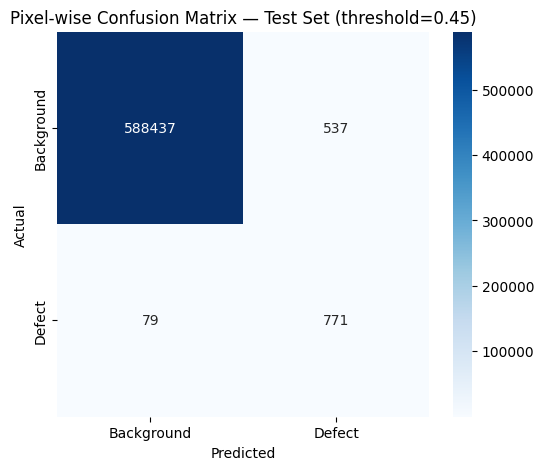

In [97]:
cm = test_metrics['confusion_matrix']

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Background', 'Defect'],
            yticklabels=['Background', 'Defect'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Pixel-wise Confusion Matrix — Test Set (threshold={BEST_THRESHOLD:.2f})')
plt.savefig('confusion_matrix_ssimrot30_f1boost.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 17 — Comparison Table

Precision / Recall / Accuracy / F1 for **Train, Validation, and Test** side by side, using the *same* trained (best-checkpoint) model and the *same* tuned threshold on each split — this shows whether the model is overfitting (train scores much higher than test) or generalizing well. Compare the **Test F1 Score** here against your earlier non-augmented, non-weighted run to see whether these changes actually helped (Step 19 has a note on doing that comparison).

In [98]:
train_metrics = evaluate(model, train_loader_eval, device, criterion, threshold=BEST_THRESHOLD)
valid_metrics = evaluate(model, valid_loader, device, criterion, threshold=BEST_THRESHOLD)
# test_metrics was already computed in Step 15

comparison_df = pd.DataFrame({
    'Dataset': ['Train', 'Validation', 'Test'],
    'Precision': [train_metrics['precision'], valid_metrics['precision'], test_metrics['precision']],
    'Recall':    [train_metrics['recall'],    valid_metrics['recall'],    test_metrics['recall']],
    'Accuracy':  [train_metrics['accuracy'],  valid_metrics['accuracy'],  test_metrics['accuracy']],
    'F1 Score':  [train_metrics['f1'],        valid_metrics['f1'],        test_metrics['f1']],
}).round(4)

comparison_df

,Dataset,Precision,Recall,Accuracy,F1 Score
0,Train,0.8164,0.9308,0.9993,0.8698
1,Validation,0.7791,0.8935,0.9990,0.8324
2,Test,0.5894,0.9071,0.9990,0.7146


## Step 18 — Visualize Predictions vs. Ground Truth

A qualitative check alongside the numbers — pulls random test images and shows the SEM image, ground-truth mask, and model prediction (at the tuned threshold) side by side.

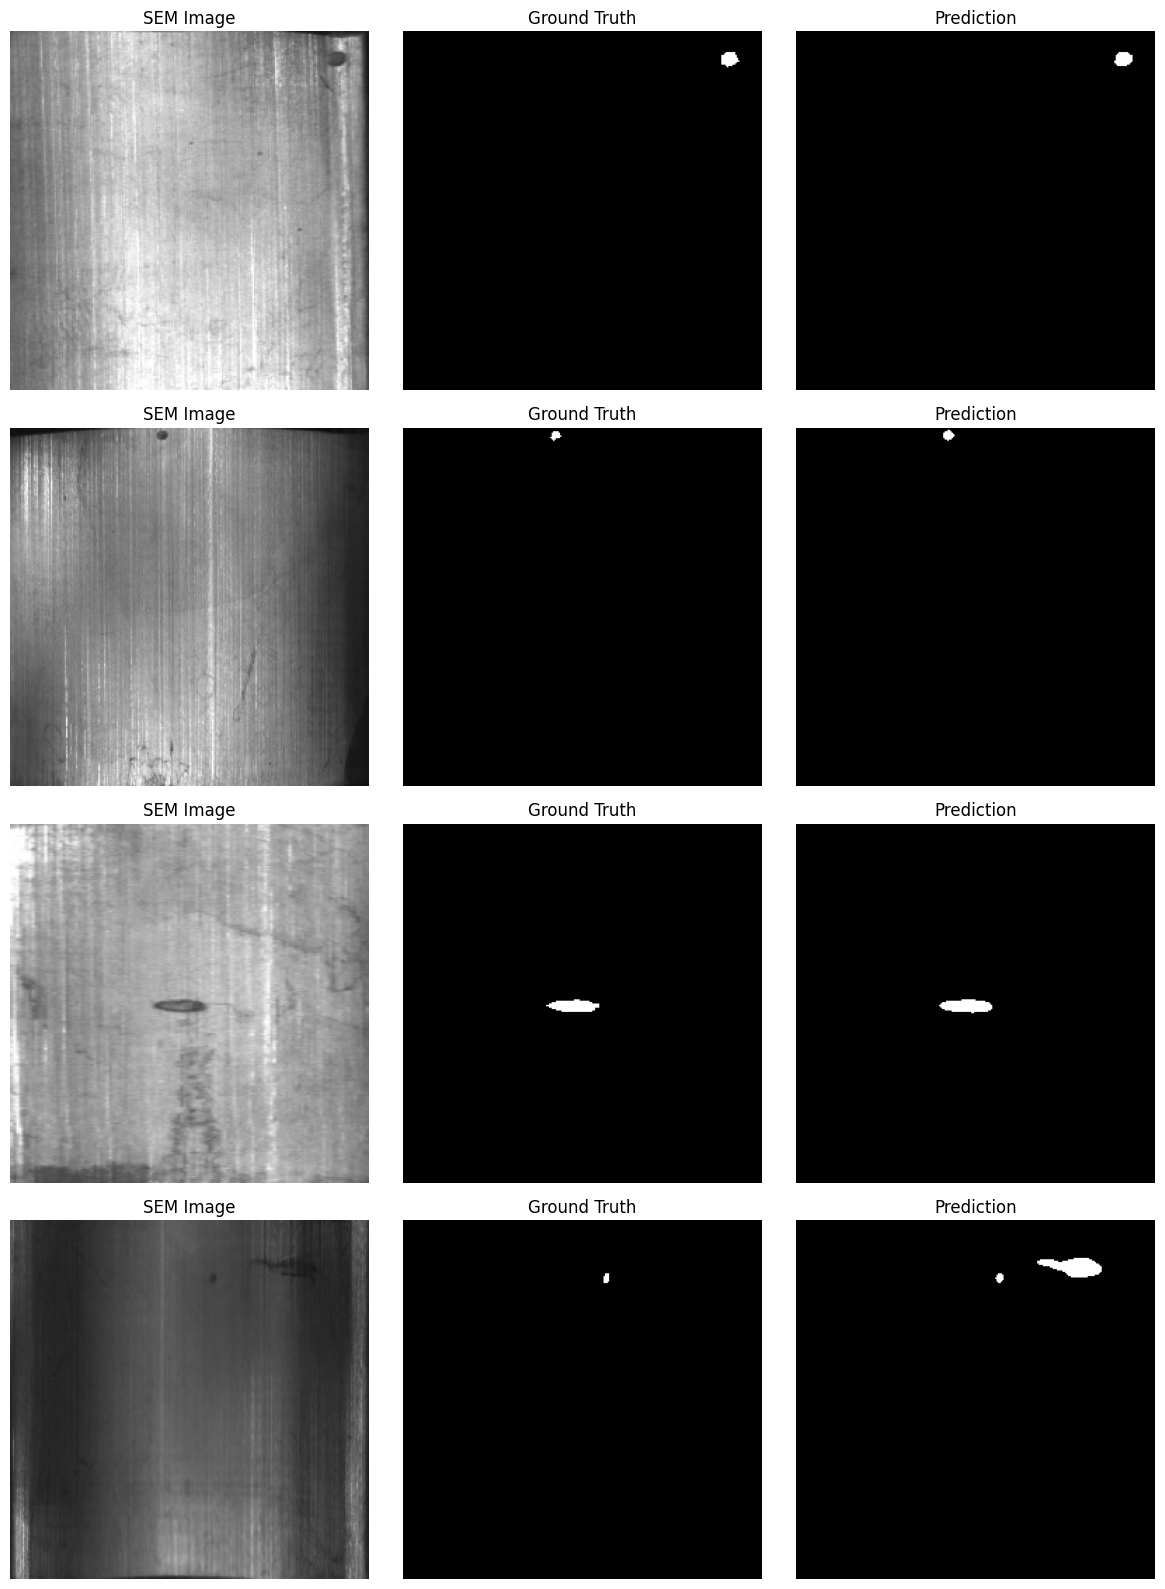

In [99]:
def visualize_predictions(model, dataset, device, threshold=0.5, num_samples=4):
    model.eval()
    num_samples = min(num_samples, len(dataset))
    indices = np.random.choice(len(dataset), num_samples, replace=False)

    fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, 3)

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for i, idx in enumerate(indices):
        image, mask = dataset[idx]
        with torch.no_grad():
            logits = model(image.unsqueeze(0).to(device))
            pred = (torch.sigmoid(logits) > threshold).float().cpu().squeeze().numpy()

        img_np = image.permute(1, 2, 0).cpu().numpy()
        img_np = np.clip(img_np * std + mean, 0, 1)

        axes[i, 0].imshow(img_np); axes[i, 0].set_title('SEM Image'); axes[i, 0].axis('off')
        axes[i, 1].imshow(mask.numpy(), cmap='gray'); axes[i, 1].set_title('Ground Truth'); axes[i, 1].axis('off')
        axes[i, 2].imshow(pred, cmap='gray'); axes[i, 2].set_title('Prediction'); axes[i, 2].axis('off')

    plt.tight_layout()
    plt.savefig('predictions_sample_ssimrot30_f1boost.png', dpi=150, bbox_inches='tight')
    plt.show()

visualize_predictions(model, test_dataset, device, threshold=BEST_THRESHOLD, num_samples=4)

## Step 19 — Save Outputs & Compare Against Your Previous Run

Outputs save with an `_ssimrot30_f1boost` suffix so they won't overwrite an earlier run's files in the same `/kaggle/working/` session — that lets you compare them side by side.

**To check whether these changes actually raised your F1 score:** open this run's `metrics_comparison_ssimrot30_f1boost.csv` next to an earlier run's `metrics_comparison.csv` (or `metrics_comparison_aug2x.csv`) and compare the **Test F1 Score** row. If you no longer have that file, rerun a previous version of this notebook once under the same conditions for a fair before/after comparison.

In [100]:
comparison_df.to_csv('/kaggle/working/metrics_comparison_ssimrot30_f1boost.csv', index=False)

import shutil
for f in ['loss_curve_ssimrot30_f1boost.png', 'confusion_matrix_ssimrot30_f1boost.png',
          'predictions_sample_ssimrot30_f1boost.png', 'threshold_sweep_ssimrot30_f1boost.png', CKPT_PATH]:
    if os.path.exists(f):
        dst = os.path.join('/kaggle/working', os.path.basename(f))
        if os.path.abspath(f) != os.path.abspath(dst):
            shutil.copy(f, dst)

print("Saved: best_unetpp_sem_wafer_ssimrot30_f1boost.pth, loss_curve_ssimrot30_f1boost.png, "
      "confusion_matrix_ssimrot30_f1boost.png, predictions_sample_ssimrot30_f1boost.png, "
      "threshold_sweep_ssimrot30_f1boost.png, metrics_comparison_ssimrot30_f1boost.csv")
print(f"\nFinal Test F1 Score (threshold={BEST_THRESHOLD:.2f}): {test_metrics['f1']:.4f}")

Saved: best_unetpp_sem_wafer_ssimrot30_f1boost.pth, loss_curve_ssimrot30_f1boost.png, confusion_matrix_ssimrot30_f1boost.png, predictions_sample_ssimrot30_f1boost.png, threshold_sweep_ssimrot30_f1boost.png, metrics_comparison_ssimrot30_f1boost.csv

Final Test F1 Score (threshold=0.45): 0.7146
